In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
import matplotlib.pyplot as plt
import numpy as np
import os
import math
from tqdm.notebook import tqdm
import warnings
import cv2
from PIL import Image
from torch.optim.lr_scheduler import LinearLR, ConstantLR, CosineAnnealingLR, SequentialLR
import torch.nn.functional as F 
from torch.optim.swa_utils import AveragedModel, update_bn
from sklearn.metrics import classification_report, confusion_matrix
import torchvision.transforms.functional as TF
import seaborn as sns

warnings.filterwarnings('ignore')

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"GPU Name: {torch.cuda.get_device_name(0)}")
    print(f"VRAM Allocated: {torch.cuda.memory_allocated(0)/1024**2:.2f} MB")

Using device: cuda
GPU Name: NVIDIA GeForce RTX 3050 6GB Laptop GPU
VRAM Allocated: 0.00 MB


In [2]:
EPOCHS = 25  
BATCH_SIZE = 16  
MAX_GRAD_NORM = 20.0  

class CLAHE_Transform(object):
    def __init__(self, clip_limit=2.0, tile_grid_size=(8, 8)):
        self.clip_limit = clip_limit
        self.tile_grid_size = tile_grid_size

    def __call__(self, img):
        img_cv = np.array(img.convert('L'))
        clahe = cv2.createCLAHE(clipLimit=self.clip_limit, tileGridSize=self.tile_grid_size)
        img_clahe = clahe.apply(img_cv)
        img_rgb = cv2.cvtColor(img_clahe, cv2.COLOR_GRAY2RGB)
        return Image.fromarray(img_rgb)

train_transforms = transforms.Compose([
    CLAHE_Transform(clip_limit=2.5, tile_grid_size=(8, 8)),
    transforms.Resize((256, 256)), 
    transforms.RandomRotation(degrees=15), 
    transforms.RandomHorizontalFlip(), 
    transforms.ColorJitter(brightness=0.15, contrast=0.15), 
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],  
                         std=[0.229, 0.224, 0.225])
])

val_test_transforms = transforms.Compose([
    CLAHE_Transform(clip_limit=2.5, tile_grid_size=(8, 8)),
    transforms.Resize((256, 256)), 
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], 
                         std=[0.229, 0.224, 0.225])
])

In [3]:
cv2.setNumThreads(0) 

data_dir = './dataset'

train_dataset = datasets.ImageFolder(os.path.join(data_dir, 'training'), transform=train_transforms)
val_dataset = datasets.ImageFolder(os.path.join(data_dir, 'validation'), transform=val_test_transforms)
test_dataset = datasets.ImageFolder(os.path.join(data_dir, 'testing'), transform=val_test_transforms)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

class_counts = [480, 1009, 670] 
total_samples = sum(class_counts)
num_classes = len(class_counts)

class_weights = [total_samples / (num_classes * count) for count in class_counts]
weights_tensor = torch.FloatTensor(class_weights).to(device)

print(f"Computed Class Weights: {weights_tensor}")

Computed Class Weights: tensor([1.4993, 0.7132, 1.0741], device='cuda:0')


In [ ]:
model = models.resnet101(weights=models.ResNet101_Weights.IMAGENET1K_V1)

for param in model.parameters():
    param.requires_grad = True

num_ftrs = model.fc.in_features
model.fc = nn.Sequential(
    nn.Dropout(p=0.2), 
    nn.Linear(num_ftrs, 3) 
)
model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=weights_tensor, label_smoothing=0.05)

optimizer = optim.AdamW([
    {'params': model.conv1.parameters(), 'lr': 5e-6},
    {'params': model.bn1.parameters(), 'lr': 5e-6},
    {'params': model.layer1.parameters(), 'lr': 5e-6},
    {'params': model.layer2.parameters(), 'lr': 1e-5},
    {'params': model.layer3.parameters(), 'lr': 5e-5},
    {'params': model.layer4.parameters(), 'lr': 5e-5},
    {'params': model.fc.parameters(), 'lr': 1e-4} 
], weight_decay=2e-2)

scaler = torch.amp.GradScaler('cuda')
history = {'train_loss': [], 'val_loss': [], 'val_acc': [], 'lrs': [], 'grad_norms': []}

In [ ]:
best_val_acc = 0.0
save_path_standard = 'best_resnet101_mri_standard.pth'
save_path_swa = 'best_resnet101_mri_swa.pth'

swa_model = AveragedModel(model)
SWA_START_EPOCH = 18 

total_steps = EPOCHS * len(train_loader)
warmup_steps = int(0.15 * total_steps)  
stable_steps = int(0.55 * total_steps)  
decay_steps = total_steps - warmup_steps - stable_steps  

warmup_sched = LinearLR(optimizer, start_factor=0.01, end_factor=1.0, total_iters=warmup_steps)
stable_sched = ConstantLR(optimizer, factor=1.0, total_iters=stable_steps)
decay_sched = CosineAnnealingLR(optimizer, T_max=decay_steps)

scheduler = SequentialLR(
    optimizer, 
    schedulers=[warmup_sched, stable_sched, decay_sched], 
    milestones=[warmup_steps, warmup_steps + stable_steps]
)

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    epoch_grad_norms = []
    
    train_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Train]")
    for inputs, labels in train_bar:
        inputs, labels = inputs.to(device), labels.to(device)
        
        optimizer.zero_grad()
        
        with torch.amp.autocast('cuda'):
            outputs = model(inputs)
            loss = criterion(outputs.float(), labels) 
            
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
        
        if not math.isinf(grad_norm.item()) and not math.isnan(grad_norm.item()):
            scaler.step(optimizer)
            
        scaler.update()
        scheduler.step()
        
        epoch_grad_norms.append(grad_norm.item())
        running_loss += loss.item()
        train_bar.set_postfix({'loss': f"{loss.item():.4f}"})
        
    avg_train_loss = running_loss / len(train_loader)
    
    if math.isnan(avg_train_loss):
        print("\n[WARNING] Training Loss is NaN. Halting training to preserve the best checkpoint.")
        break

    avg_grad_norm = np.nanmean(epoch_grad_norms)
    current_lr = optimizer.param_groups[-1]['lr'] 
    
    model.eval()
    val_loss = 0.0
    correct = 0
    total = 0
    
    with torch.no_grad():
        val_bar = tqdm(val_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Val]", leave=False)
        for inputs, labels in val_bar:
            inputs, labels = inputs.to(device), labels.to(device)
            
            with torch.amp.autocast('cuda'):
                outputs = model(inputs)
                loss = criterion(outputs.float(), labels)
                
            val_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
            
    avg_val_loss = val_loss / len(val_loader)
    val_acc = 100 * correct / total
    
    history['train_loss'].append(avg_train_loss)
    history['val_loss'].append(avg_val_loss)
    history['val_acc'].append(val_acc)
    history['grad_norms'].append(avg_grad_norm)
    history['lrs'].append(current_lr)
    
    print(f"Epoch {epoch+1}: Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val Acc: {val_acc:.2f}%")
    
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), save_path_standard)
        print(f"--> Saved new best model with Val Acc: {best_val_acc:.2f}%")
        
    if epoch + 1 >= SWA_START_EPOCH:
        swa_model.update_parameters(model)
        print(f"--> SWA: Averaged weights for epoch {epoch+1}")

print("\nTraining Complete! Updating SWA Batch Normalization statistics...")
update_bn(train_loader, swa_model, device=device)
torch.save(swa_model.state_dict(), save_path_swa)
print("Saved SWA Model as:", save_path_swa)

Epoch 1/25 [Train]:   0%|          | 0/68 [00:00<?, ?it/s]

Epoch 1/25 [Val]:   0%|          | 0/13 [00:00<?, ?it/s]

Epoch 1: Train Loss: 1.0915 | Val Loss: 1.0438 | Val Acc: 64.52%
--> Saved new best model with Val Acc: 64.52%


Epoch 2/25 [Train]:   0%|          | 0/68 [00:00<?, ?it/s]

Epoch 2/25 [Val]:   0%|          | 0/13 [00:00<?, ?it/s]

Epoch 2: Train Loss: 0.8230 | Val Loss: 0.6129 | Val Acc: 79.43%
--> Saved new best model with Val Acc: 79.43%


... (65 outputs left out)

Epoch 24: Train Loss: 0.1906 | Val Loss: 0.3867 | Val Acc: 91.77%
--> SWA: Averaged weights for epoch 24


Epoch 25/25 [Train]:   0%|          | 0/68 [00:00<?, ?it/s]

Epoch 25/25 [Val]:   0%|          | 0/13 [00:00<?, ?it/s]

Epoch 25: Train Loss: 0.1915 | Val Loss: 0.3615 | Val Acc: 92.54%
--> SWA: Averaged weights for epoch 25

Training Complete! Updating SWA Batch Normalization statistics...
Saved SWA Model as: best_resnet50_mri_swa.pth


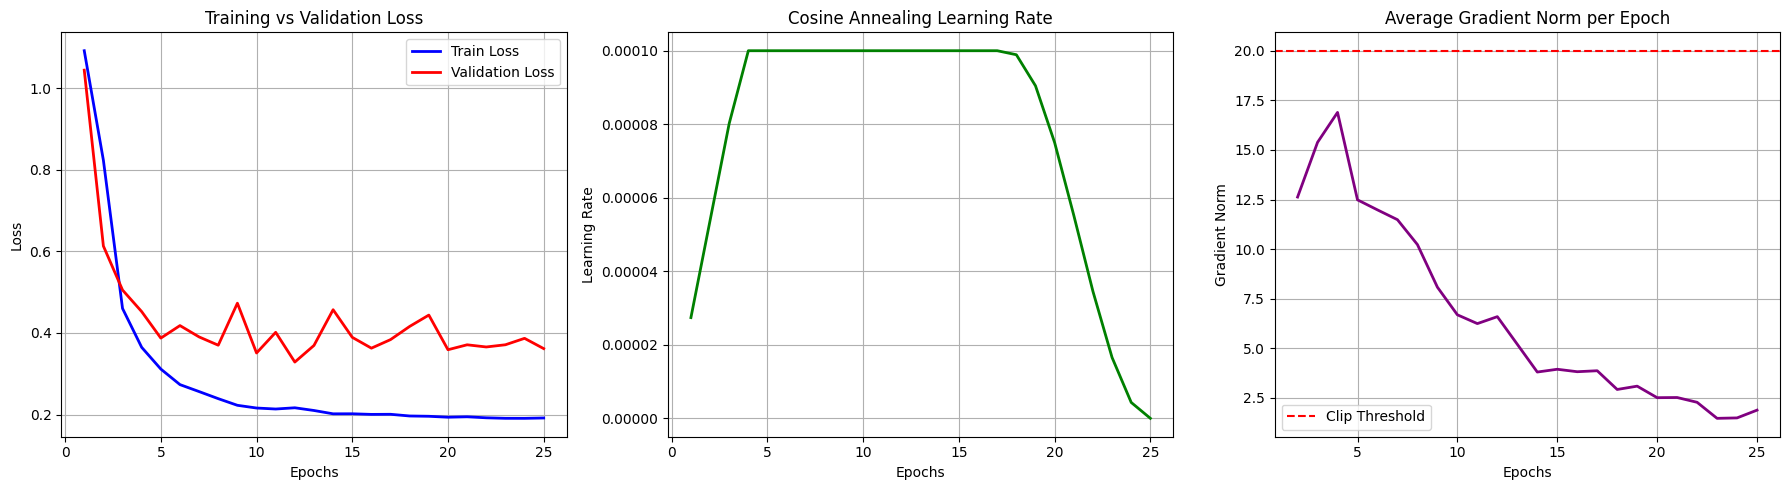

In [ ]:
epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
plt.plot(epochs_range, history['train_loss'], label='Train Loss', color='blue', linewidth=2)
plt.plot(epochs_range, history['val_loss'], label='Validation Loss', color='red', linewidth=2) 
plt.title('Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 3, 2)
plt.plot(epochs_range, history['lrs'], color='green', linewidth=2)
plt.title('Cosine Annealing Learning Rate')
plt.xlabel('Epochs')
plt.ylabel('Learning Rate')
plt.grid(True)

plt.subplot(1, 3, 3)
plt.plot(epochs_range, history['grad_norms'], color='purple', linewidth=2)
plt.axhline(y=MAX_GRAD_NORM, color='r', linestyle='--', label='Clip Threshold')
plt.title('Average Gradient Norm per Epoch')
plt.xlabel('Epochs')
plt.ylabel('Gradient Norm')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Evaluating test set with Bilateral TTA (No Rotation)...


Testing:   0%|          | 0/33 [00:00<?, ?it/s]


--- Final Classification Report (SWA + Bilateral TTA) ---
              precision    recall  f1-score   support

  Meningioma     0.8750    0.9655    0.9180       145
      Glioma     0.9829    0.9544    0.9684       241
   Pituitary     0.9754    0.9154    0.9444       130

    accuracy                         0.9477       516
   macro avg     0.9444    0.9451    0.9436       516
weighted avg     0.9507    0.9477    0.9482       516



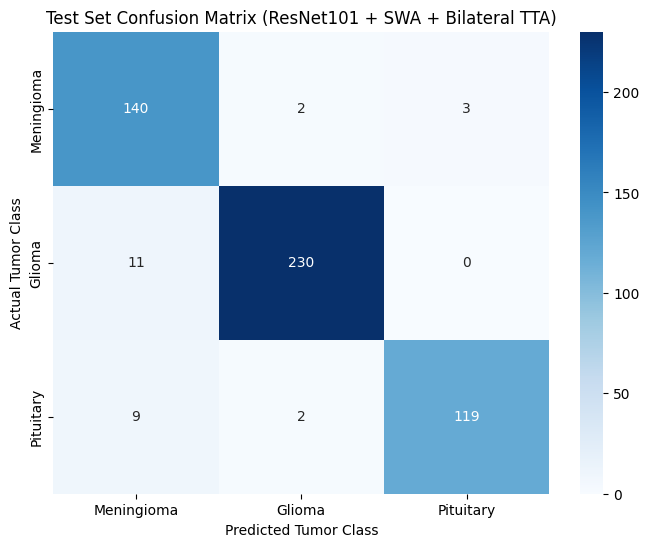

In [5]:
model_eval = AveragedModel(models.resnet101(weights=None))
num_ftrs = model_eval.module.fc.in_features
model_eval.module.fc = nn.Sequential(
    nn.Dropout(p=0.2), 
    nn.Linear(num_ftrs, 3)
)

model_eval.load_state_dict(torch.load('models/best_resnet101_mri_swa.pth', map_location=device))
model_eval = model_eval.to(device)
model_eval.eval()

all_preds = []
all_labels = []

print("Evaluating test set with Bilateral TTA (No Rotation)...")
with torch.no_grad():
    for inputs, labels in tqdm(test_loader, desc="Testing"):
        inputs, labels = inputs.to(device), labels.to(device)
        
        with torch.amp.autocast('cuda'):
            out_orig = model_eval(inputs)
            
            inputs_flip = torch.flip(inputs, dims=[3])
            out_flip = model_eval(inputs_flip)
            
            avg_probs = (F.softmax(out_orig, dim=1) + F.softmax(out_flip, dim=1)) / 2.0
            
        _, predicted = torch.max(avg_probs, 1)
        
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

class_names = ['Meningioma', 'Glioma', 'Pituitary']

print("\n--- Final Classification Report (SWA + Bilateral TTA) ---")
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Test Set Confusion Matrix (ResNet101 + SWA + Bilateral TTA)')
plt.ylabel('Actual Tumor Class')
plt.xlabel('Predicted Tumor Class')
plt.show()